In [73]:
import yfinance as yf

test = yf.download(["GTCO.LG", "ZENITHBANK.LG", "DANGCEM.LG"], start="2021-01-01", auto_adjust=True)["Close"]
print(test.tail())
print(test.isna().mean())

$GTCO.LG: possibly delisted; no timezone found


$ZENITHBANK.LG: possibly delisted; no timezone found
[                       0%                       ]$DANGCEM.LG: possibly delisted; no timezone found
[*********************100%***********************]  3 of 3 completed

3 Failed downloads:
['GTCO.LG', 'ZENITHBANK.LG', 'DANGCEM.LG']: possibly delisted; no timezone found


Empty DataFrame
Columns: [DANGCEM.LG, GTCO.LG, ZENITHBANK.LG]
Index: []
Ticker
DANGCEM.LG      NaN
GTCO.LG         NaN
ZENITHBANK.LG   NaN
dtype: float64


In [74]:
import pandas as pd
from pathlib import Path

frames = {}
for f in Path("../data").glob("*.csv"):
    df = pd.read_csv(f)
    df.columns = [c.strip().lower() for c in df.columns]
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.dropna(subset=["date"]).set_index("date").sort_index()
    col = "price" if "price" in df.columns else "close"
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", ""), errors="coerce")
    frames[f.stem] = df[col]

prices = pd.DataFrame(frames).sort_index()
print(prices.shape)
print(prices.head())
print(prices.tail())
print(prices.isna().mean())


KeyError: 'close'

In [ ]:
prices.columns = [c.replace(".csv", "") for c in prices.columns]


In [ ]:
mtn_raw = pd.read_csv("../data/mtn.csv.csv")
print(mtn_raw.shape)
print(mtn_raw.head(3))
print(mtn_raw.tail(3))


(939, 7)
         Date  Price   Open   High    Low     Vol. Change %
0  10/19/2026  825.0  825.0  825.0  825.0    1.41M    0.00%
1  10/16/2026  825.0  820.0  825.0  825.0  892.74K    0.61%
2  10/15/2026  820.0  844.0  820.0  820.0    1.21M   -2.84%
           Date  Price   Open   High    Low     Vol. Change %
936  01/05/2023  215.0  215.0  216.5  215.0  379.63K    0.00%
937  01/04/2023  215.0  215.0  215.0  215.0  772.00K    0.00%
938  01/03/2023  215.0  215.0  218.0  211.5  497.34K    0.00%


In [ ]:
print(prices.isna().mean())

dangote          0.003185
guarantytrust    0.002123
mtn              0.003185
nestle           0.004246
seplat           0.001062
zenith           0.001062
dtype: float64


In [ ]:
r = prices.pct_change()
print(r.abs().max())
print(r["seplat"].abs().sort_values(ascending=False).head(5))

dangote          0.100000
guarantytrust    0.119403
mtn              0.100000
nestle           0.100000
seplat           0.100002
zenith           0.120032
dtype: float64
date
2024-01-19    0.100002
2024-01-23    0.100001
2026-02-12    0.100000
2026-02-05    0.100000
2026-04-30    0.100000
Name: seplat, dtype: float64


In [ ]:
prices = prices.ffill(limit=5)
returns = prices.pct_change().dropna(how="all")

print(prices.isna().sum())
print(returns.shape)    #cleaning data for anomalies and mkissing values

dangote          0
guarantytrust    0
mtn              0
nestle           0
seplat           0
zenith           0
dtype: int64
(941, 6)


In [ ]:
print(returns.abs().max())
print(returns["seplat"].abs().sort_values(ascending=False).head(5))

dangote          0.100000
guarantytrust    0.119403
mtn              0.100000
nestle           0.100000
seplat           0.100002
zenith           0.120032
dtype: float64
date
2024-01-19    0.100002
2024-01-23    0.100001
2026-01-07    0.100000
2026-04-30    0.100000
2025-05-29    0.100000
Name: seplat, dtype: float64


In [ ]:
prices.to_csv("../data/prices_clean.csv")

In [ ]:
Path("../data/processed").mkdir(exist_ok=True)
prices.to_csv("../data/processed/prices_clean.csv")

In [75]:
vol = returns.std() * (252 ** 0.5)
print(vol.sort_values(ascending=False))

zenith           0.389828
guarantytrust    0.376753
mtn              0.374693
dangote          0.342162
seplat           0.308435
nestle           0.281976
dtype: float64


In [76]:
from pathlib import Path
for f in Path("../data").glob("*.csv"):
    print(f.name)

dangote.csv.csv
guarantytrust.csv.csv
mtn.csv.csv
nestle.csv.csv
prices_clean.csv
seplat.csv.csv
zenith.csv.csv


In [77]:
Path("../data/processed").mkdir(exist_ok=True)
Path("../data/prices_clean.csv").rename("../data/processed/prices_clean.csv")

WindowsPath('../data/processed/prices_clean.csv')

In [78]:
from pathlib import Path
for f in Path("../data").glob("*.csv"):
    print(f.name)

dangote.csv.csv
guarantytrust.csv.csv
mtn.csv.csv
nestle.csv.csv
seplat.csv.csv
zenith.csv.csv


In [79]:
prices.columns = [c.replace(".csv", "") for c in prices.columns]


In [80]:
prices = prices.ffill(limit=5)
returns = prices.pct_change().dropna(how="all")
print(returns.shape)

(941, 6)


In [81]:
vol = returns.std() * (252 ** 0.5)
vol.sort_values(ascending=False)

zenith           0.389828
guarantytrust    0.376753
mtn              0.374693
dangote          0.342162
seplat           0.308435
nestle           0.281976
dtype: float64

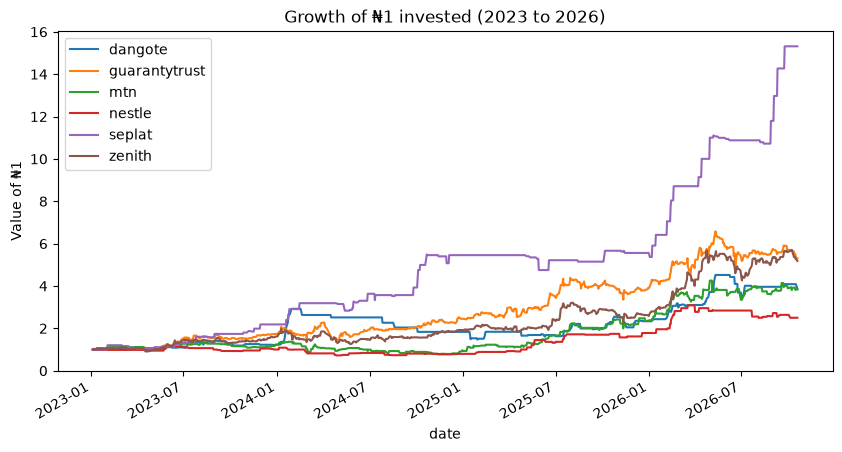

In [82]:
import matplotlib.pyplot as plt

growth = (1 + returns).cumprod()
growth.plot(figsize=(10, 5), title="Growth of ₦1 invested (2023 to 2026)")
plt.ylabel("Value of ₦1")
plt.show()

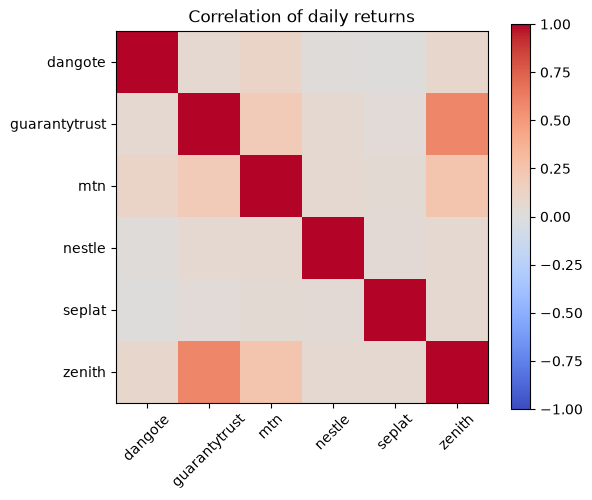

In [83]:
corr = returns.corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im)
ax.set_title("Correlation of daily returns")
plt.show()

In [84]:
growth.iloc[-1].sort_values(ascending=False)


seplat           15.315937
guarantytrust     5.290323
zenith            5.183946
dangote           3.862069
mtn               3.837209
nestle            2.500000
Name: 2026-10-19 00:00:00, dtype: float64

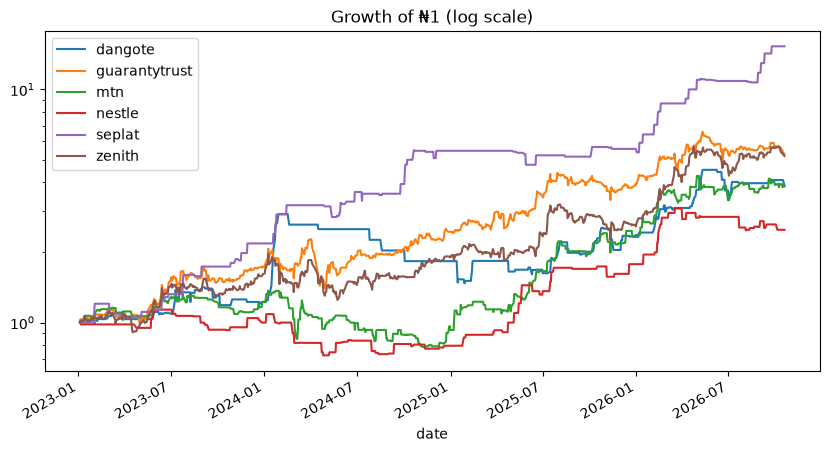

In [85]:
growth.plot(figsize=(10, 5), logy=True, title="Growth of ₦1 (log scale)")
plt.show()

In [86]:
growth.iloc[-1].sort_values(ascending=False)

seplat           15.315937
guarantytrust     5.290323
zenith            5.183946
dangote           3.862069
mtn               3.837209
nestle            2.500000
Name: 2026-10-19 00:00:00, dtype: float64

In [87]:
print(corr.round(2))

               dangote  guarantytrust   mtn  nestle  seplat  zenith
dangote           1.00           0.06  0.11    0.02    0.01    0.09
guarantytrust     0.06           1.00  0.19    0.06    0.04    0.59
mtn               0.11           0.19  1.00    0.07    0.05    0.24
nestle            0.02           0.06  0.07    1.00    0.04    0.06
seplat            0.01           0.04  0.05    0.04    1.00    0.06
zenith            0.09           0.59  0.24    0.06    0.06    1.00


In [88]:
weekly = prices.resample("W").last().pct_change().dropna(how="all")
print(weekly.corr().round(2))


               dangote  guarantytrust   mtn  nestle  seplat  zenith
dangote           1.00           0.02  0.17    0.04    0.21    0.07
guarantytrust     0.02           1.00  0.26    0.10    0.14    0.59
mtn               0.17           0.26  1.00    0.26    0.16    0.33
nestle            0.04           0.10  0.26    1.00    0.07    0.16
seplat            0.21           0.14  0.16    0.07    1.00    0.09
zenith            0.07           0.59  0.33    0.16    0.09    1.00


In [89]:
import numpy as np

mean_ret = returns.mean().values * 252      # average yearly return per stock
cov = returns.cov().values * 252            # yearly risk and co-movement table
n = len(mean_ret)

np.random.seed(42)
rows = []
for _ in range(30000):
    w = np.random.random(n)
    w = w / w.sum()                         # weights now add up to 1 (100%)
    if w.max() > 0.30:                      # skip if any stock is over 30%
        continue
    ret = w @ mean_ret                      # portfolio return
    vol = np.sqrt(w @ cov @ w)              # portfolio risk
    rows.append([ret, vol, ret / vol] + list(w))

port = pd.DataFrame(rows, columns=["ret", "vol", "sharpe"] + list(returns.columns))
print(len(port))

18052


Best risk-adjusted:
 ret              0.515
vol              0.165
sharpe           3.123
dangote          0.172
guarantytrust    0.143
mtn              0.106
nestle           0.228
seplat           0.295
zenith           0.056
Name: 5638, dtype: float64
Lowest risk:
 ret              0.487
vol              0.163
sharpe           2.996
dangote          0.187
guarantytrust    0.129
mtn              0.109
nestle           0.292
seplat           0.253
zenith           0.031
Name: 15212, dtype: float64


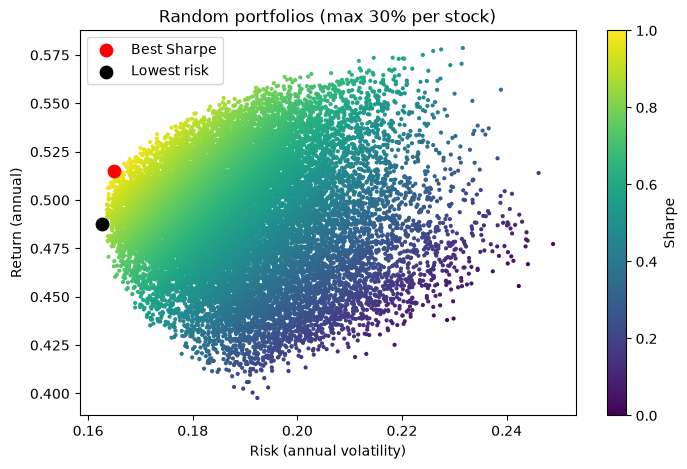

In [90]:
best = port.loc[port["sharpe"].idxmax()]
safest = port.loc[port["vol"].idxmin()]
print("Best risk-adjusted:\n", best.round(3))
print("Lowest risk:\n", safest.round(3))

plt.figure(figsize=(8, 5))
plt.scatter(port["vol"], port["ret"], c=port["sharpe"], s=4, cmap="viridis")
plt.scatter(best["vol"], best["ret"], c="red", s=80, label="Best Sharpe")
plt.scatter(safest["vol"], safest["ret"], c="black", s=80, label="Lowest risk")
plt.xlabel("Risk (annual volatility)")
plt.ylabel("Return (annual)")
plt.colorbar(label="Sharpe")
plt.legend()
plt.title("Random portfolios (max 30% per stock)")
plt.show()

In [91]:
plt.savefig("../frontier.png", dpi=150)

<Figure size 640x480 with 0 Axes>

In [92]:
rf = 0.20   # replace with the real current rate as a decimal
port["sharpe_rf"] = (port["ret"] - rf) / port["vol"]
best_rf = port.loc[port["sharpe_rf"].idxmax()]
print(best_rf.round(3))

ret              0.534
vol              0.173
sharpe           3.084
dangote          0.210
guarantytrust    0.122
mtn              0.155
nestle           0.115
seplat           0.298
zenith           0.100
sharpe_rf        1.929
Name: 16478, dtype: float64


In [93]:
rf = 0.17   # 364-day T-bill, roughly 16.85% to 17.15%
port["sharpe_rf"] = (port["ret"] - rf) / port["vol"]
best_rf = port.loc[port["sharpe_rf"].idxmax()]
print(best_rf.round(3))

ret              0.534
vol              0.173
sharpe           3.084
dangote          0.210
guarantytrust    0.122
mtn              0.155
nestle           0.115
seplat           0.298
zenith           0.100
sharpe_rf        2.102
Name: 16478, dtype: float64
